# **IS 4487 Assignment 9: Customer Segmentation with Clustering**

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Business Context: Hotel Bookings

### Dataset Description:

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, clustering, and trend analysis exercises.

## **Task 1. Import libraries, Load the Data and Preview it**

Business framing:  

Before we can cluster or segment anything, we need clean, accessible data in a usable format.

1.1. Import the necessary Python libraries

1.2. Load the hotel bookings dataset into a Dataframe [use this link: https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv

1.3. Display the first few rows

1.4. Show summary statistics for the Dataframe



In [1]:
# 🔧 1.1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 🔧 1.2. Load the data
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)

# 🔧 1.3. Preview the first few rows
display(df.head())

# 🔧 1.4. Summary statistics
display(df.describe())

# Extra checks to back up the 1.4 answer
print(df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


children         4
country        488
agent        16340
company     112593
dtype: int64
Duplicate rows: 31994


### ✍️ Please answer the following:

1.4. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response:

1.4. A few things stand out. The 'adr' column has a negative minimum and a max of 5,400, which look like errors. Some bookings have 0 adults, and one has 55. 'lead_time' goes up to 737 days, which is over two years out. The 'company' column is missing most of its values, and 'agent' is missing a lot too. There are also about 32,000 duplicate rows.

## **Task 2. Select and Prepare Features**

Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

2.1. Choose 3-5 numeric features related to customer behavior. Write a comment on what variables you chose

2.2. For these columns, perform any cleaning/ pre-processing steps as you see fit (drop missing values, remove outliers, remove duplicates, correct datatypes)

2.3. Standardize using `StandardScaler`

2.4. `.describe()`  the standardized columns after converting the output of StandardScaler to a Dataframe first to ensure that mean = 0 and std.dev = 1



In [2]:
# 🔧 2.1. Features chosen: lead_time, adr, total_of_special_requests, total_nights
# total_nights is a new column: weekend nights + week nights
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
features = ["lead_time", "adr", "total_of_special_requests", "total_nights"]

# 🔧 2.2. Clean the data
df_clean = df.drop_duplicates().copy()

# Remove bookings that don't make sense
df_clean = df_clean[(df_clean["adr"] > 0) &
                    (df_clean["total_nights"] > 0) &
                    (df_clean["adults"] > 0)]

# Remove the top 1% of outliers
for col in ["lead_time", "adr", "total_nights"]:
    df_clean = df_clean[df_clean[col] <= df_clean[col].quantile(0.99)]

df_clean = df_clean.reset_index(drop=True)
print("Rows after cleaning:", len(df_clean))

# 🔧 2.3. Standardize
scaler = StandardScaler()
scaled = scaler.fit_transform(df_clean[features])

# 🔧 2.4. Convert to a Dataframe and check mean = 0 and std = 1
df_scaled = pd.DataFrame(scaled, columns=features)
df_scaled.describe().round(2)

Rows after cleaning: 83329


,lead_time,adr,total_of_special_requests,total_nights
count,83329.00,83329.00,83329.00,83329.00
mean,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.97,-2.27,-0.84,-1.07
25%,-0.82,-0.69,-0.84,-0.65
50%,-0.36,-0.17,0.36,-0.24
75%,0.57,0.58,0.36,0.59
max,3.37,3.31,5.19,4.30


### ✍️ Please answer the following:

2.5. What features did you select and why?

2.6. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response:
2.5. I chose 'lead_time', 'adr', 'total_of_special_requests', and 'total_nights'. Together they show how far ahead guests book, how much they pay, how much service they want, and how long they stay.

2.6. I expect to see last minute guests on short trips, guests who plan ahead for longer vacations, and a higher spending group that makes more special requests.

## **Task 3. Apply K-Means Clustering**

Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

3.1. Fit a `KMeans` model with your selected features. Choose a value of `k` (e.g. 3, 4, or 5)

3.2. Predict clusters and assign a cluster number to each guest

3.3. Add the predicted values back to the scaled Dataframe. Write code to view the counts of observations in each cluster, sorted in a meaningful way.

3.4. Visualize using a scatterplot of 2 key features to show the different clusters (colors) that were identified (optionally use a third feature for size or a fourth feature for style)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.



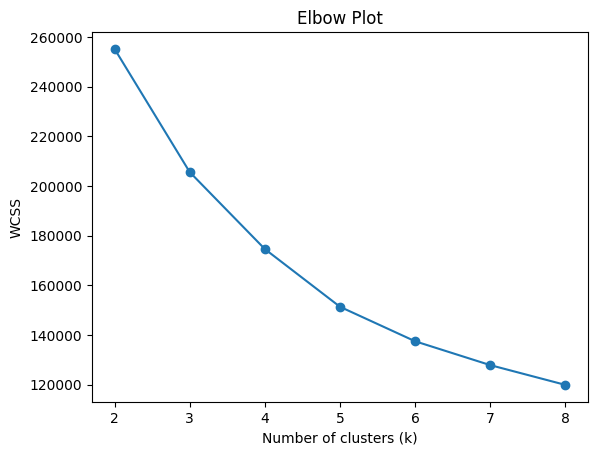

kmeans_cluster
3    35113
0    18330
2    17883
1    12003
Name: count, dtype: int64


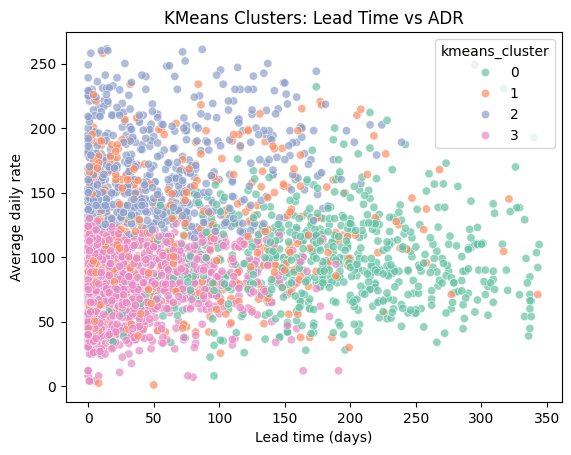

,lead_time,adr,total_of_special_requests,total_nights
kmeans_cluster,,,,
0,183.78,97.31,0.54,5.95
1,71.91,117.56,2.23,3.41
2,54.75,165.39,0.52,3.25
3,35.09,78.73,0.35,2.57


In [3]:
# Elbow check to help pick k
wcss = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(df_scaled[features])
    wcss.append(model.inertia_)

plt.plot(range(2, 9), wcss, marker="o")
plt.title("Elbow Plot")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.show()

# 🔧 3.1. Fit KMeans with k = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(df_scaled[features])

# 🔧 3.2. Predict a cluster for each guest
kmeans_labels = kmeans.predict(df_scaled[features])

# 🔧 3.3. Add clusters back and count them, largest first
df_scaled["kmeans_cluster"] = kmeans_labels
df_clean["kmeans_cluster"] = kmeans_labels
print(df_scaled["kmeans_cluster"].value_counts().sort_values(ascending=False))

# 🔧 3.4. Scatterplot (uses a sample of 3,000 so the dots don't pile up)
plot_data = df_clean.sample(3000, random_state=42)
sns.scatterplot(data=plot_data, x="lead_time", y="adr",
                hue="kmeans_cluster", palette="Set2", alpha=0.7)
plt.title("KMeans Clusters: Lead Time vs ADR")
plt.xlabel("Lead time (days)")
plt.ylabel("Average daily rate")
plt.show()

# Cluster averages for 3.6, in real units
display(df_clean.groupby("kmeans_cluster")[features].mean().round(2))

### ✍️ Please answer the following:

3.5. What `k` value did you choose, and how did you decide?

3.6. What types of customers seem to show up in the clusters?

*HINT: To answer this you need to obtain summary statistics for the chosen features for each cluster to see which variables are most prominent or important for that cluster. You can add this code above. THis is what will allow you to *label* or identify what each cluster represents.*

### ✍️ Your Response:
3.5. I chose k = 4. The elbow plot starts to level off around there, and 4 groups is easy for a marketing team to use.

3.6. Cluster 0 are early planners who book far ahead and stay longer. Cluster 1 are guests who make a lot of special requests. Cluster 2 are premium guests who pay the most per night. Cluster 3 are budget guests who book late and take short trips.

## **Task 4. Apply Gaussian Mixture Model (GMM)**

Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

4.1. Fit a GMM with the same number of clusters you chose in Part 3

4.2. Obtain the predicted GMM cluster for each observation (assigned to cluster with the max probabilty automatically). Write code to view the counts of observations in each cluster, sorted in a meaningful way

4.3. Predict soft clusters (remember that soft clustering deals with probabilities, not labels). Show the cluster probabilities for 5 sample observations/customer records.

4.4. Visualize the GMM model so that you may compare it to the KMeans scatterplot using the same/similar chart as you created for Kmeans above

4.5. Write code to cross-tabulate the KMeans and GMM cluster predictions. This will show you where their predictions are consistent (or vary).

Ensure that all outputs 4.2-4.5 are showing below. Use print() if needed or separate the code into separate cells.


gmm_cluster
1    41652
3    19605
0    16816
2     5256
Name: count, dtype: int64


,Cluster 0,Cluster 1,Cluster 2,Cluster 3
0,0.000,1.0,0.000,0.000
1,0.000,1.0,0.000,0.000
2,0.978,0.0,0.001,0.021
3,0.000,1.0,0.000,0.000
4,0.698,0.0,0.286,0.016


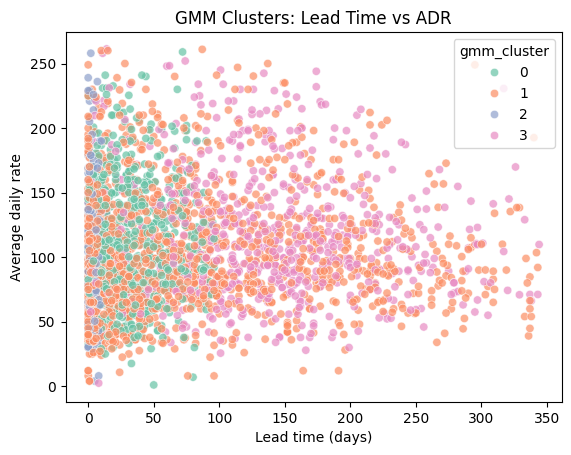

gmm_cluster,0,1,2,3
kmeans_cluster,,,,
0,9,9902,0,8419
1,3256,0,1404,7343
2,5412,8991,1012,2468
3,8139,22759,2840,1375


,lead_time,adr,total_of_special_requests,total_nights
gmm_cluster,,,,
0,34.24,113.65,1.20,2.94
1,74.67,100.68,0.00,3.48
2,2.78,101.49,1.31,1.34
3,139.90,116.23,1.59,4.93


In [4]:
# 🔧 4.1. Fit GMM with the same number of clusters
gmm = GaussianMixture(n_components=4, random_state=42, n_init=3)
gmm.fit(df_scaled[features])

# 🔧 4.2. Hard clusters and counts, largest first
gmm_labels = gmm.predict(df_scaled[features])
df_scaled["gmm_cluster"] = gmm_labels
df_clean["gmm_cluster"] = gmm_labels
print(df_scaled["gmm_cluster"].value_counts().sort_values(ascending=False))

# 🔧 4.3. Soft clusters: probabilities for 5 guests
probs = gmm.predict_proba(df_scaled[features])
probs_df = pd.DataFrame(probs, columns=["Cluster 0", "Cluster 1", "Cluster 2", "Cluster 3"])
display(probs_df.head(5).round(3))

# 🔧 4.4. Same scatterplot as KMeans, using the same 3,000 guests
plot_data = df_clean.sample(3000, random_state=42)
sns.scatterplot(data=plot_data, x="lead_time", y="adr",
                hue="gmm_cluster", palette="Set2", alpha=0.7)
plt.title("GMM Clusters: Lead Time vs ADR")
plt.xlabel("Lead time (days)")
plt.ylabel("Average daily rate")
plt.show()

# 🔧 4.5. Cross-tab of KMeans vs GMM
display(pd.crosstab(df_scaled["kmeans_cluster"], df_scaled["gmm_cluster"]))

# Cluster averages to help with 4.6
display(df_clean.groupby("gmm_cluster")[features].mean().round(2))

### ✍️ Please answer the following:

4.6. How did the GMM results compare to KMeans? You can compare visualizations or cross-tabulations/contingency tables.


### ✍️ Your Response:
4.6. KMeans and GMM grouped guests differently. KMeans split guests mostly by lead time and price, so its scatterplot shows clear groups. The GMM plot looks more mixed because GMM split guests mostly by special requests. GMM cluster 1 is all guests who made zero requests. The cross-tab shows the models don't line up that much, most KMeans clusters spread across several GMM clusters.

## **Task 5. Evaluate Your Models**

Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics, such as
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

5.1. - 5.2. Compare above metrics for both models - K-Means and GMM clusters

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering


In [5]:
X = df_scaled[features]

# 🔧 5.1. KMeans metrics
km_wcss = kmeans.inertia_
km_sil = silhouette_score(X, df_scaled["kmeans_cluster"], sample_size=10000, random_state=42)
km_db = davies_bouldin_score(X, df_scaled["kmeans_cluster"])

# 🔧 5.2. GMM metrics
# GMM doesn't give WCSS, so we add it up for each cluster
gmm_wcss = 0
for cluster in df_scaled["gmm_cluster"].unique():
    points = X[df_scaled["gmm_cluster"] == cluster]
    gmm_wcss += ((points - points.mean()) ** 2).sum().sum()

gmm_sil = silhouette_score(X, df_scaled["gmm_cluster"], sample_size=10000, random_state=42)
gmm_db = davies_bouldin_score(X, df_scaled["gmm_cluster"])

results = pd.DataFrame({
    "Model": ["KMeans", "GMM"],
    "WCSS": [km_wcss, gmm_wcss],
    "Silhouette": [km_sil, gmm_sil],
    "Davies-Bouldin": [km_db, gmm_db]
})
display(results.round(3))

,Model,WCSS,Silhouette,Davies-Bouldin
0,KMeans,174574.871,0.262,1.247
1,GMM,236472.028,0.078,2.238


### ✍️ Please answer the following:

5.3. Which model performed better on the metrics?

5.4. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response:
5.3. KMeans did better on all three metrics. It had lower WCSS, a higher silhouette score, and a lower Davies-Bouldin index.

5.4. I would recommend KMeans. It scored better and is easier to explain to a business team.

## **Task 6. Business Interpretation**

Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers? For this part, choose whichever cluster model gave the best output for you.

6.1. Obtain summary statistics for relevant characteristics/variables of each cluster (e.g. average `lead_time`, `special_requests` even if they were not chosen to create clusters) to help you compare the clusters meaningfully.
  - TIP: if you obtains means of unstandardized variables, they will be easier to interpret, but standardized variables are fine too.
  - TIP: Think from a marketing or hotel operations perspective.



In [6]:
# 🔧 6.1. Average of each variable by KMeans cluster
summary_cols = ["lead_time", "adr", "total_of_special_requests", "total_nights",
                "is_canceled", "adults", "children", "is_repeated_guest",
                "booking_changes", "required_car_parking_spaces"]

display(df_clean.groupby("kmeans_cluster")[summary_cols].mean().round(2).T)

kmeans_cluster,0,1,2,3
lead_time,183.78,71.91,54.75,35.09
adr,97.31,117.56,165.39,78.73
total_of_special_requests,0.54,2.23,0.52,0.35
total_nights,5.95,3.41,3.25,2.57
is_canceled,0.37,0.19,0.36,0.21
adults,1.95,2.00,2.06,1.72
children,0.10,0.17,0.30,0.04
is_repeated_guest,0.01,0.03,0.01,0.06
booking_changes,0.33,0.29,0.25,0.22
required_car_parking_spaces,0.05,0.10,0.10,0.09


### ✍️ Please answer the following:

6.2. What do the segments represent in terms of guest behavior?

6.3. How could the hotel tailor services or promotions to each group?


### ✍️ Your Response:
6.2. Cluster 0 books early and stays long. Cluster 1 makes the most requests. Cluster 2 pays the most. Cluster 3 books late and pays the least.

6.3. Cluster 0 could get early booking deals. Cluster 1 could get add-ons. Cluster 2 could get family packages. Cluster 3 could get last minute deals.

## **Task 7. Final Reflection**

Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### ✍️ Please answer the following:

7.1. What was most challenging about unsupervised learning?

7.2. When would you use clustering instead of supervised models?

7.3. How would you explain the value of clustering to a non-technical manager?

7.4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response:
7.1. The hardest part was that there are no right answers to check against. I had to choose k myself and figure out what each cluster meant.

7.2. I would use clustering when there is no label to predict and I just want to find groups in the data. Supervised models are better when I know the outcome I want to predict.

7.3. Clustering sorts customers into groups that act alike. Then we can market to each group differently instead of sending everyone the same thing.

7.4. My learning outcome was using data to solve real business problems and knowing where to start with a dataset. This assignment did both. I started by looking for problems in the data, then cleaned it, then turned the clusters into marketing ideas for the hotel.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Save the file with your last name and first name as shown below (see detailed instructions in Lab 1 on how to do this).
- Submit the assignment as an **HTML file** on Canvas


In [7]:
!jupyter nbconvert --to html "assignment_09_MaaloufNoelle.ipynb"

[NbConvertApp] Converting notebook assignment_09_MaaloufNoelle.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 941880 bytes to assignment_09_MaaloufNoelle.html
